In [1]:
'''
crossmatching best candidates
'''

'\ncrossmatching best candidates\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner
from astropy.wcs import WCS
import shutil
from astroquery.gaia import Gaia
from astropy.coordinates import SkyCoord
import astropy.units as u
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

Matplotlib is building the font cache; this may take a moment.


In preparation for Gaia DR4, the Gaia archive is in evolution. Unfortunately, it may be unstable at times and particular types of queries may time out. Please consider registering for a user account (https://www.cosmos.esa.int/web/gaia-users/register). For questions or advice, please contact the Gaia helpdesk (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk).


In [3]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [4]:
final_df = pd.read_csv('/home/3155/final_df_for_now')

In [106]:
def query_gaia_for_stars(olddf, radius=9):
    """
    Query Gaia DR3 to match stars in the given DataFrame based on RA and Dec.
    Adds Gaia source ID, magnitude (G, BP-RP, RP, BP), and variability information.
    Additionally checks if the star is listed in the Gaia DR3 vari_summary table.
    
    Parameters:
        df (pd.DataFrame): DataFrame with 'ra' and 'dec' columns.
        radius (float): Search radius in arcseconds.
        
    Returns:
        pd.DataFrame: Updated DataFrame with Gaia data.
    """
    df = olddf.copy()
    # df[['gaia_source_id', 'g_mag', 'bp_rp', 'r_mag', 'i_mag', 'variability', 'in_vari_summary']
    gaia_columns = [
        'source_id', 'ra', 'dec', 'phot_g_mean_mag', 'bp_rp', 'phot_rp_mean_mag', 'phot_bp_mean_mag', 'phot_variable_flag'
    ]
    
    new_data = []
    
    for _, row in df.iterrows():
        if pd.isna(row['star_ra']) or pd.isna(row['star_dec']):
                print("NaN coordinate, skipping Gaia query for this row.")
                new_data.append([None, None, None, None, None])
                continue
        coord = SkyCoord(ra=row['star_ra']*u.deg, dec=row['star_dec']*u.deg, frame='icrs')
        
        query = f"""
        SELECT TOP 1 {', '.join(gaia_columns)} FROM gaiadr3.gaia_source
        WHERE CONTAINS(POINT('ICRS', ra, dec), 
                       CIRCLE('ICRS', {row['star_ra']}, {row['star_dec']}, {radius}/3600.0))=1
        ORDER BY ztf_ri_gaia_rp_mag ASC
        """ #just swapped the order so now it's by RI
        if row['Band']=='g':
            query = f"""
        SELECT TOP 1 {', '.join(gaia_columns)} FROM gaiadr3.gaia_source
        WHERE CONTAINS(POINT('ICRS', ra, dec), 
                       CIRCLE('ICRS', {row['star_ra']}, {row['star_dec']}, {radius}/3600.0))=1
        ORDER BY phot_bp_mean_mag ASC
        """ 
        else:
            query = f"""
        SELECT TOP 1 {', '.join(gaia_columns)} FROM gaiadr3.gaia_source
        WHERE CONTAINS(POINT('ICRS', ra, dec), 
                       CIRCLE('ICRS', {row['star_ra']}, {row['star_dec']}, {radius}/3600.0))=1
        ORDER BY phot_rp_mean_mag ASC
        """ 
        
        job = Gaia.launch_job(query)
        results = job.get_results()
        
        if len(results) > 0:
            best_match = results[0]
            source_id = best_match['source_id']
            
            # Check if the star is in the vari_summary table
            var_query = f"""
            SELECT COUNT(*) AS var_count FROM gaiadr3.vari_summary
            WHERE source_id = {source_id}
            """
            var_job = Gaia.launch_job(var_query)
            var_results = var_job.get_results()
            is_variable = var_results['var_count'][0] > 0
            
            new_data.append([
                source_id, 
                    best_match['phot_bp_mean_mag'], best_match['phot_rp_mean_mag'],
                best_match['phot_variable_flag'],
                is_variable
            ])
        else:
            new_data.append([None, None, None, None, None])
    
    df[['gaia_source_id',  'ztf_g_gaia_bp_rp_mag', 'ztf_ri_gaia_rp_mag',  'variability', 'in_vari_summary']] = new_data
    return df

In [19]:
np.full(2, np.nan)

array([nan, nan])

In [26]:



def add_ra_dec(olddf):
    fpath_header = "/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/"
    df = olddf.copy()
    df['star_ra']=np.full(len(df), np.nan)
    df['star_dec']=np.full(len(df), np.nan)
    for index, row in df.iterrows():
        image_filename = row['filename']
        # print(image_filename[:-6])
        quad = row['quadrant']
        
        xy_file = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/" + image_filename[:-6] + "_" + str(quad) + ".fits"
        header_file = fpath_header + image_filename[:-6] + "_" + str(quad) + ".wcs"
        # print(header_file)
    
        try:
            with fits.open(xy_file) as hdul_xy:
                data = hdul_xy[1].data  
                stored_x = data["X"]
                stored_y = data["Y"]
        except Exception as e:
            print(f"Could not open xy_file: {xy_file} — {e}")
            stored_x = stored_y = None
    
        try:
            with fits.open(header_file) as hdul_header:
                wcs = WCS(hdul_header[0].header, relax=True)
        except Exception as e:
            print(f"Could not open header_file: {header_file} — {e}")
            wcs = None
    
        if stored_x is not None and stored_y is not None and wcs is not None:
            closest_x, closest_y = row['closest_x'], row['closest_y']
            ra, dec = wcs.all_pix2world(closest_x, closest_y, True)
            df.loc[index, 'star_ra' ] = ra
            df.loc[index, 'star_dec' ] = dec
    return df


In [27]:
newdf = add_ra_dec(final_df)

In [28]:
newdf

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,...,num_in_file_in_star,global_noise_over_average,concat_index_copy,snr,real_type,distance_from_start,num_simultaneous_20_p1_space,num_simultaneous_20_p1_time,star_ra,star_dec
0,265333,265333,3,4,ztf_20221020297847_000449_zr_c09_x_0013.,2,pos,1959.500000,3035.000000,2,...,3.0,0.033064,265333,2.732394,neg,-1456.500000,[265333],[265333],21.247100,6.259387
1,340170,340170,0,0,ztf_20221020294271_000449_zr_c14_x_0016.,3,pos,69.500000,229.000000,2,...,5.0,0.037400,340170,2.645553,neg,2764.500000,[340170],[340170],20.172300,6.621466
2,163212,163212,30,2,ztf_20221020148032_000686_zg_c09_x_0028.,2,pos,11.000000,1922.000000,3,...,4.0,0.044745,163212,2.505133,neg,726.000000,"[163212, 163198, 163216, 163242]",[163212],301.056392,34.955815
3,83421,83421,32,2,ztf_20221020148032_000686_zg_c09_x_0029.,2,pos,11.000000,1922.000000,3,...,4.0,0.044745,83421,2.470651,neg,726.000000,"[83421, 83403, 83404, 83425, 83451]",[83421],301.056392,34.955815
4,142569,142569,19,18,ztf_20221020297847_000449_zr_c05_x_0016.,4,pos,1960.200000,2419.600000,5,...,4.0,0.053767,142569,2.165144,neg,-1208.200000,[142569],[142569],22.282015,3.373425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,233380,233380,8,40,ztf_20221020154120_000640_zi_c04_x_0029.,2,pos,1972.000000,948.500000,6,...,2.0,0.036287,233380,1.668402,neg,185.000000,[233380],[233380],297.468430,23.533984
72,109844,109844,71,14,ztf_20221020148032_000686_zg_c03_x_0020.,3,pos,592.884615,2997.076923,26,...,2.0,0.054820,109844,1.661622,neg,552.115385,"[109844, 109801]",[109844],296.258720,30.137813
73,303126,303126,49,63,ztf_20221020163819_000640_zg_c15_x_0008.,2,pos,2414.000000,2220.500000,2,...,6.0,0.051017,303126,1.658292,neg,-2137.000000,"[303126, 303095, 303119, 303136]",[303126],299.024561,29.829349
74,111115,111115,8,5,ztf_20221020297847_000449_zr_c15_x_0004.,3,pos,1859.888889,1349.777778,9,...,2.0,0.039833,111115,1.657009,neg,-777.888889,[111115],[111115],17.993132,7.110703


In [62]:
df_3 = query_gaia_for_stars(df, 3)

In [63]:
df_9 = query_gaia_for_stars(df, 9)

In [46]:
df = query_gaia_for_stars(df)

In [64]:
np.sum(df_3['gaia_source_id']==df_9['gaia_source_id'])

43

In [65]:
np.sum(df['gaia_source_id']==df_9['gaia_source_id'])

65

In [100]:
def add_band(df):
    band = []
    for i, row in df.iterrows():
        band.append(row['filename'][27])
    df["Band"] = band
    return df

In [40]:
df = add_band(df)

In [ ]:
df

In [37]:
np.unique(newdf['star_ra'], return_counts=True)

(array([ 17.03437892,  17.06467188,  17.08917435,  17.18475825,
         17.2237275 ,  17.25703806,  17.99313219,  19.76463591,
         20.05158437,  20.1722518 ,  20.17229967,  20.26732369,
         20.84839664,  20.84841072,  20.95846124,  21.00734288,
         21.24710025,  21.28640836,  21.65397328,  22.28201544,
         22.78823321, 294.72534672, 294.79340046, 295.19565412,
        295.86555181, 295.87478135, 296.04051967, 296.25871984,
        296.74546316, 296.95079319, 297.03467032, 297.14150467,
        297.30144947, 297.3716607 , 297.46842951, 297.56256913,
        297.58559367, 297.6252261 , 297.75756034, 298.20424547,
        298.21683736, 298.43605839, 298.53228014, 298.83333729,
        298.90217011, 299.02456144, 299.19148067, 299.29425284,
        299.69720999, 300.03548866, 300.15713509, 300.18085993,
        300.31147859, 300.6741357 , 300.9275491 , 301.05639245,
        301.4800861 , 301.77958336, 301.97264116, 302.15390193,
        302.43862854, 302.47679974, 302.

In [66]:
df_nodups = df_9.drop_duplicates('gaia_source_id')
g_stars = df_nodups[df_nodups['Band']=="g"]
r_stars = df_nodups[df_nodups['Band']=="r"]
i_stars = df_nodups[df_nodups['Band']=="i"]

In [67]:
min_ri = min(pd.to_numeric(df_nodups['ztf_ri_gaia_rp_mag'], 'coerce'))
max_ri = max(pd.to_numeric(df_nodups['ztf_ri_gaia_rp_mag'], 'coerce'))

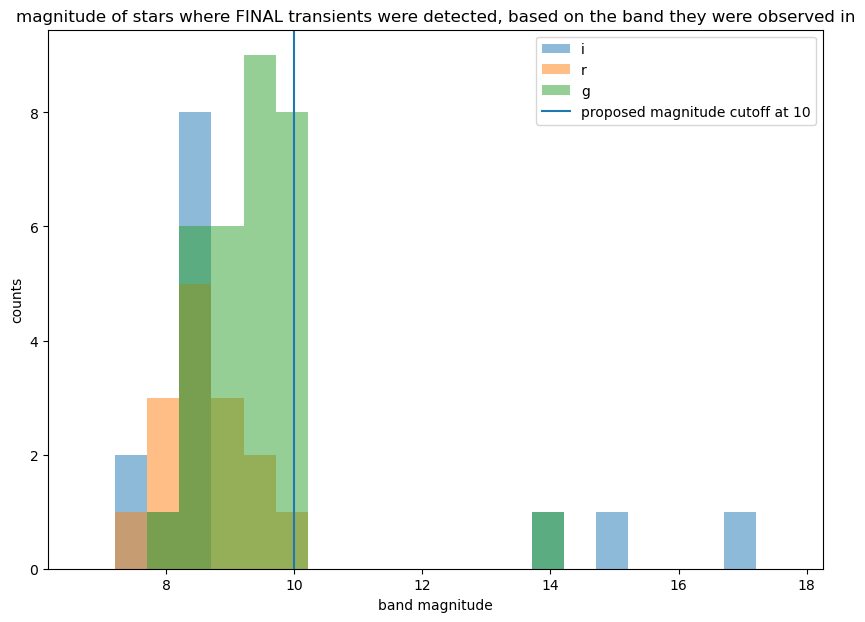

In [68]:
binwidth=.5
plt.hist(pd.to_numeric(i_stars['ztf_ri_gaia_rp_mag'], 'coerce'), 
         alpha=.5,label='i', 
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(r_stars['ztf_ri_gaia_rp_mag'], 'coerce'), alpha=.5,label='r',
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(g_stars['ztf_g_gaia_bp_rp_mag'], 'coerce'), alpha=.5,label='g',
        bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.title("magnitude of stars where FINAL transients were detected, based on the band they were observed in")
plt.ylabel("counts")
plt.xlabel("band magnitude")
plt.axvline(10, label="proposed magnitude cutoff at 10")
plt.legend()

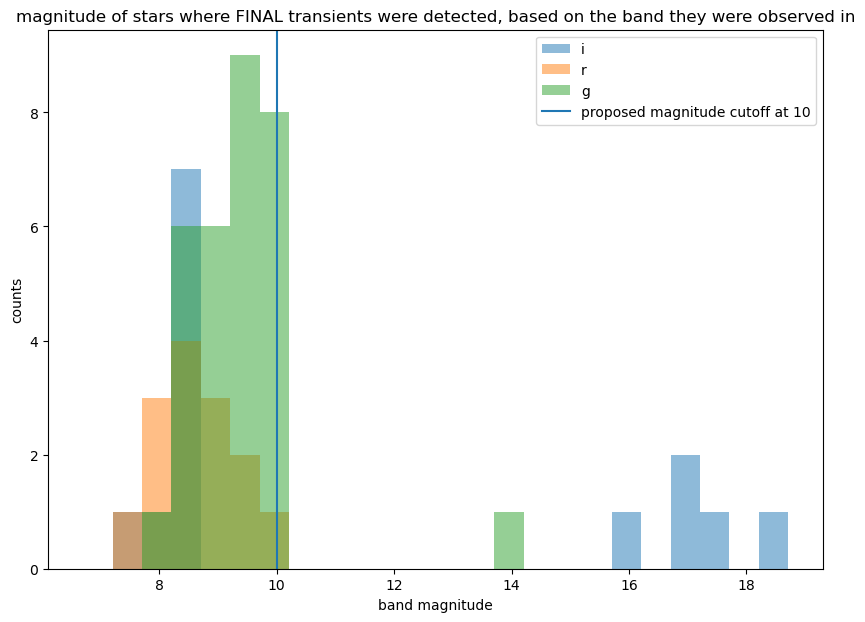

In [53]:
binwidth=.5
plt.hist(pd.to_numeric(i_stars['ztf_ri_gaia_rp_mag'], 'coerce'), 
         alpha=.5,label='i', 
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(r_stars['ztf_ri_gaia_rp_mag'], 'coerce'), alpha=.5,label='r',
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(g_stars['ztf_g_gaia_bp_rp_mag'], 'coerce'), alpha=.5,label='g',
        bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.title("magnitude of stars where FINAL transients were detected, based on the band they were observed in")
plt.ylabel("counts")
plt.xlabel("band magnitude")
plt.axvline(10, label="proposed magnitude cutoff at 10")
plt.legend()

In [54]:
concat = add_band(concat)

In [55]:
nodupsconcat = concat.drop_duplicates(subset=["closest_x", 'filename','quad'])

In [58]:
len(nodupsconcat)

96844

In [60]:
nodupsconcat.to_csv('/home/3155/nodupsconcat')

In [59]:
nodupsconcat = add_ra_dec(nodupsconcat)

KeyboardInterrupt: 

In [69]:
#it would be so chill if i could do exactly the same thing for training
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/df_implants_neg")


In [72]:
df_implants_total = df_implants_pos.append(df_implants_neg)

/tmp/ipykernel_1823/1507311770.py:1: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_implants_total = df_implants_pos.append(df_implants_neg)


In [75]:
df_implants_total

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,0,ztf_20221020148032_000686_zg_c03_x_0011.,190.0,71.0,1.005,4.0,2
1,1,ztf_20221020148032_000686_zg_c03_x_0011.,191.0,685.0,1.010,5.0,2
2,2,ztf_20221020148032_000686_zg_c03_x_0011.,190.0,1289.0,10.000,3.0,2
3,3,ztf_20221020148032_000686_zg_c03_x_0011.,191.0,1798.0,1.200,8.0,2
4,4,ztf_20221020148032_000686_zg_c03_x_0011.,190.0,2449.0,1.050,6.0,2
...,...,...,...,...,...,...,...
795,795,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,120.0,0.950,5.0,3
796,796,ztf_20221020154120_000640_zi_c03_x_0002.,3000.0,685.0,0.995,4.0,3
797,797,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1240.0,0.950,4.0,3
798,798,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1843.0,0.400,7.0,3


In [89]:
df_implants_total_almost_unique

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,0,ztf_20221020148032_000686_zg_c03_x_0011.,190.0,71.0,1.005,4.0,2
1,1,ztf_20221020148032_000686_zg_c03_x_0011.,191.0,685.0,1.010,5.0,2
5,5,ztf_20221020148032_000686_zg_c03_x_0011.,592.0,42.0,1.200,5.0,2
6,6,ztf_20221020148032_000686_zg_c03_x_0011.,593.0,680.0,1.400,7.0,2
10,10,ztf_20221020148032_000686_zg_c03_x_0011.,927.0,49.0,1.010,5.0,2
...,...,...,...,...,...,...,...
786,786,ztf_20221020154120_000640_zi_c03_x_0002.,2429.0,630.0,0.700,4.0,3
790,790,ztf_20221020154120_000640_zi_c03_x_0002.,2522.0,115.0,0.990,9.0,3
791,791,ztf_20221020154120_000640_zi_c03_x_0002.,2521.0,701.0,0.500,5.0,3
795,795,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,120.0,0.950,5.0,3


In [88]:
df_implants_total_almost_unique = df_implants_total.drop_duplicates(subset=['filename','quad_from_implant','row_from_implant'])

In [93]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [94]:
df_implants_total_almost_unique = rff.match_stars_eff(df_implants_total_almost_unique)

/home/3155/rwe/review_findings_functions.py:2529: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['closest_x'] = closest_xs
/home/3155/rwe/review_findings_functions.py:2530: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['closest_y']= closest_ys
/home/3155/rwe/review_findings_functions.py:2531: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/

In [96]:
df_implants_total_almost_unique = df_implants_total_almost_unique.drop_duplicates(subset=['filename','quad_from_implant','closest_x'])

In [99]:
df_implants_total_almost_unique

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant,closest_x,closest_y,Diff,brightness_ranking
0,0,ztf_20221020148032_000686_zg_c03_x_0011.,190.0,71.0,1.005,4.0,2,152.0,2812.0,81.0,20.0
1,1,ztf_20221020148032_000686_zg_c03_x_0011.,191.0,685.0,1.010,5.0,2,734.0,1048.0,49.0,12.0
16,16,ztf_20221020148032_000686_zg_c03_x_0011.,1120.0,651.0,1.050,8.0,2,594.0,382.0,-57.0,9.0
29,29,ztf_20221020148032_000686_zg_c03_x_0011.,1246.0,2361.0,1.100,5.0,2,2381.0,512.0,20.0,22.0
33,33,ztf_20221020148032_000686_zg_c03_x_0011.,1689.0,1843.0,7.000,6.0,2,1869.0,2558.0,26.0,18.0
...,...,...,...,...,...,...,...,...,...,...,...
746,746,ztf_20221020154120_000640_zi_c03_x_0002.,2988.0,659.0,0.700,4.0,4,553.0,1495.0,-106.0,3.0
750,750,ztf_20221020154120_000640_zi_c03_x_0002.,77.0,103.0,0.400,7.0,3,78.0,2297.0,-25.0,0.0
761,761,ztf_20221020154120_000640_zi_c03_x_0002.,537.0,666.0,0.300,5.0,3,562.0,793.0,-104.0,21.0
772,772,ztf_20221020154120_000640_zi_c03_x_0002.,842.0,1208.0,0.700,3.0,3,995.0,2093.0,-213.0,9.0


In [101]:
df_implants_total_almost_unique = add_band(df_implants_total_almost_unique)

/tmp/ipykernel_1823/4123152484.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Band"] = band


In [103]:
df_implants_total_almost_unique['quadrant']=df_implants_total_almost_unique['quad_from_implant']

/tmp/ipykernel_1823/3246454453.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_implants_total_almost_unique['quadrant']=df_implants_total_almost_unique['quad_from_implant']


In [104]:
df_implants_total_almost_unique = add_ra_dec(df_implants_total_almost_unique)

In [107]:
df_implants_total_unique = query_gaia_for_stars(df_implants_total_almost_unique)

In [32]:
plt.rcParams.update({'font.size': 12})
df_nodups = df_implants_total_unique.drop_duplicates('gaia_source_id')
g_stars = df_nodups[df_nodups['Band']=="g"]
r_stars = df_nodups[df_nodups['Band']=="r"]
i_stars = df_nodups[df_nodups['Band']=="i"]
min_ri = min(pd.to_numeric(df_nodups['ztf_ri_gaia_rp_mag'], 'coerce'))
max_ri = max(pd.to_numeric(df_nodups['ztf_ri_gaia_rp_mag'], 'coerce'))
binwidth=.5
plt.hist(pd.to_numeric(i_stars['ztf_ri_gaia_rp_mag'], 'coerce'), 
         alpha=.5,label='i', 
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))

plt.hist(pd.to_numeric(g_stars['ztf_g_gaia_bp_rp_mag'], 'coerce'), alpha=.5,label='g',
        bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(r_stars['ztf_ri_gaia_rp_mag'], 'coerce'), alpha=.5,label='r',
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.title("Magnitude of Stars in Training Data")
plt.ylabel("Number of Stars")
plt.xlabel("Magnitude")
plt.axvline(12, label="Magnitude cutoff at 12")
plt.legend()

NameError: name 'df_implants_total_unique' is not defined

In [115]:
concat.to_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_with_band')

In [11]:
partial_0 = np.load("/lustre/lrspec/ZTF_data/gaia_partial.npy", allow_pickle=True)

In [5]:
partial = np.load("/lustre/lrspec/ZTF_data/gaia_partial_1.npy", allow_pickle=True)

In [7]:
len(partial)

20276

In [9]:
nodupsconcat = pd.read_csv('/home/3155/nodupsconcat')

In [12]:
len(nodupsconcat)-len(partial)-len(partial_0)

51140

In [14]:
partial_0 = np.load("/lustre/lrspec/ZTF_data/gaia_partial.npy", allow_pickle=True)
partial_1 = np.load("/lustre/lrspec/ZTF_data/gaia_partial_1.npy", allow_pickle=True)
partial_2 = np.load("/lustre/lrspec/ZTF_data/gaia_partial_2.npy", allow_pickle=True)
partial_3 = np.load("/lustre/lrspec/ZTF_data/gaia_partial_3.npy", allow_pickle=True)
partial_4 = np.load("/lustre/lrspec/ZTF_data/gaia_partial_4.npy", allow_pickle=True)

In [16]:
partials = np.vstack((partial_0,partial_1,partial_2,partial_3,partial_4))

In [17]:
partials

array([[2035389610115262464, 7.681032, 5.996903, 'NOT_AVAILABLE', False],
       [2035381741734755712, 17.16429, 15.771725, 'NOT_AVAILABLE', False],
       [2060120375407807744, 6.6486673, 6.7548995, 'VARIABLE', True],
       ...,
       [1833794531094244992, 21.463408, 19.455437, 'NOT_AVAILABLE',
        False],
       [2538316124224549376, 6.65597, 5.602451, 'NOT_AVAILABLE', False],
       [2027266452550234368, 8.909404, 8.619046, 'NOT_AVAILABLE', False]],
      dtype=object)

In [19]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [21]:
nodupsconcat = pd.read_csv('/home/3155/nodupsconcat')

nodupsconcat = rff.add_ra_dec(nodupsconcat)

Could not open header_file: /lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020141806_000686_zi_c11_x_4.wcs — name 'WCS' is not defined
Could not open header_file: /lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020141806_000686_zi_c11_x_4.wcs — name 'WCS' is not defined
Could not open header_file: /lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020148032_000686_zg_c14_x_1.wcs — name 'WCS' is not defined
Could not open header_file: /lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020148032_000686_zg_c14_x_1.wcs — name 'WCS' is not defined
Could not open header_file: /lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020297847_000449_zr_c13_x_3.wcs — name 'WCS' is not defined
Could not open header_file: /lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020297847_000449_zr_c13_x_3.wcs — name 'WCS' is not defined
Could not open h


KeyboardInterrupt



In [ ]:
nodupsconcat[['gaia_source_id',  'ztf_g_gaia_bp_rp_mag', 'ztf_ri_gaia_rp_mag',  'variability', 'in_vari_summary']] = partials


nodupsconcat.to_csv('/home/3155/nodupsconcat_gaia')

In [23]:
nodupsconcat = pd.read_csv('/home/3155/nodupsconcat_gaia')

In [25]:
nodupsconcat = rff.add_band(nodupsconcat)

In [26]:
nodupsconcat[nodupsconcat['Band']

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,...,quadrant,num_in_file_in_star,Band,star_ra,star_dec,gaia_source_id,ztf_g_gaia_bp_rp_mag,ztf_ri_gaia_rp_mag,variability,in_vari_summary
0,0,0,0,0,0,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,686.500000,907.000000,...,4,6.0,i,297.936995,34.070166,2.035390e+18,7.681032,5.996903,NOT_AVAILABLE,False
1,1,6,6,6,5,ztf_20221020141806_000686_zi_c11_x_0017.,4,pos,2213.500000,1236.000000,...,4,2.0,i,297.826269,33.970001,2.035382e+18,17.16429,15.771725,NOT_AVAILABLE,False
2,2,8,8,0,19,ztf_20221020148032_000686_zg_c14_x_0017.,1,pos,1849.000000,1058.500000,...,1,3.0,g,300.186657,36.590441,2.060120e+18,6.6486673,6.7548995,VARIABLE,True
3,3,11,11,3,0,ztf_20221020148032_000686_zg_c14_x_0017.,1,pos,10.961538,1683.884615,...,1,17.0,g,299.979978,37.042865,2.060190e+18,5.08798,5.292495,NOT_AVAILABLE,False
4,4,28,28,0,3,ztf_20221020297847_000449_zr_c13_x_0026.,3,pos,271.000000,945.000000,...,3,6.0,r,21.841155,6.962251,2.566094e+18,8.549382,7.349151,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96839,96839,347411,347411,41,19,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,795.875000,2277.500000,...,3,2.0,i,303.156495,24.639279,1.833727e+18,10.69216,8.80754,NOT_AVAILABLE,False
96840,96840,347413,347413,43,9,ztf_20221020157697_000640_zi_c05_x_0024.,3,pos,472.666667,2705.833333,...,3,7.0,i,303.026580,24.757101,1.833776e+18,9.443525,7.9427323,NOT_AVAILABLE,False
96841,96841,347420,347420,50,34,ztf_20221020157697_000640_zi_c05_x_0024.,3,both,1247.214286,2904.642857,...,3,2.0,i,302.968568,24.925386,1.833795e+18,21.463408,19.455437,NOT_AVAILABLE,False
96842,96842,347422,347422,0,0,ztf_20221020294271_000449_zr_c04_x_0003.,1,pos,830.857143,1381.857143,...,1,1.0,r,16.999227,1.991218,2.538316e+18,6.65597,5.602451,NOT_AVAILABLE,False


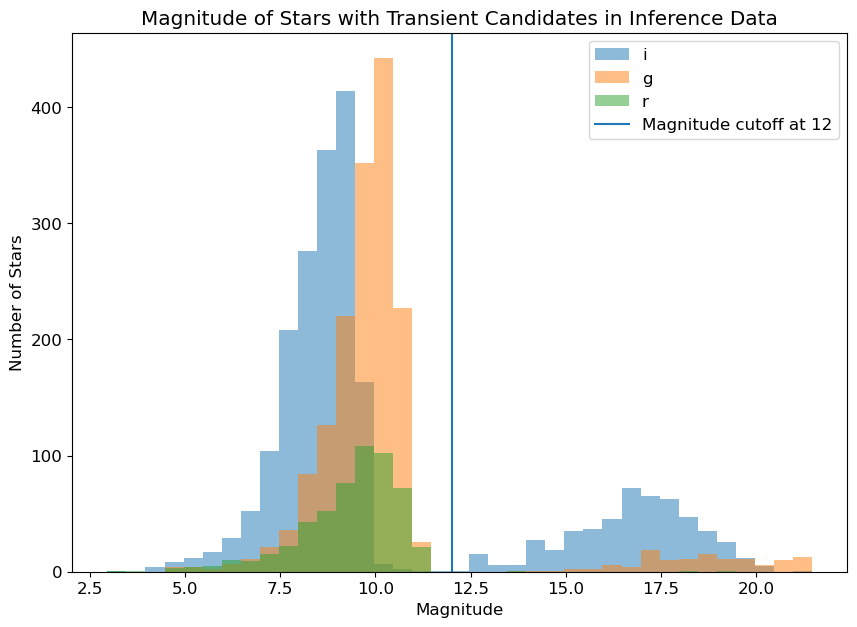

In [33]:
plt.rcParams.update({'font.size': 12})
df_nodups = nodupsconcat.drop_duplicates('gaia_source_id')
g_stars = df_nodups[df_nodups['Band']=="g"]
r_stars = df_nodups[df_nodups['Band']=="r"]
i_stars = df_nodups[df_nodups['Band']=="i"]
min_ri = min(pd.to_numeric(df_nodups['ztf_ri_gaia_rp_mag'], 'coerce'))
max_ri = max(pd.to_numeric(df_nodups['ztf_ri_gaia_rp_mag'], 'coerce'))
binwidth=.5
plt.hist(pd.to_numeric(i_stars['ztf_ri_gaia_rp_mag'], 'coerce'), 
         alpha=.5,label='i', 
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))

plt.hist(pd.to_numeric(g_stars['ztf_g_gaia_bp_rp_mag'], 'coerce'), alpha=.5,label='g',
        bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(r_stars['ztf_ri_gaia_rp_mag'], 'coerce'), alpha=.5,label='r',
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.title("Magnitude of Stars with Transient Candidates in Inference Data")
plt.ylabel("Number of Stars")
plt.xlabel("Magnitude")
plt.axvline(12, label="Magnitude cutoff at 12")
plt.legend()